# Cải thiện mô hình dự đoán giá: target giá/m² và đặc trưng giá khu vực

Thử 2 hướng cải thiện trên XGBoost (mô hình champion v11), giữ nguyên siêu tham số và cách chia train/test:

1. **Đổi target**: dự đoán `log(giá / m²)` thay vì `log(giá)`, rồi nhân lại diện tích.
2. **Thêm đặc trưng giá khu vực**: giá/m² trung bình (có làm mượt) theo phường × loại hình,
   đường × loại hình, dự án, quận × loại con, kèm số tin của mỗi nhóm.

So sánh 4 cấu hình (A = v11 hiện tại, B = chỉ hướng 1, D = chỉ hướng 2, C = cả hai).
Mỗi cấu hình chạy 3 seed để biết chênh lệch có lớn hơn dao động ngẫu nhiên không.

**Chạy:** cần MinIO (`docker compose up -d minio`).

## 1. Đọc dữ liệu và chia train/test theo thời gian

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deltalake import DeltaTable
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder
from xgboost import XGBRegressor

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e3", "axes.axisbelow": True})
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9a9893"

STORAGE = {
    "AWS_ENDPOINT_URL": os.getenv("MINIO_ENDPOINT", "http://localhost:9000"),
    "AWS_ACCESS_KEY_ID": os.getenv("MINIO_ACCESS_KEY", "minio"),
    "AWS_SECRET_ACCESS_KEY": os.getenv("MINIO_SECRET_KEY", "minio123"),
    "AWS_REGION": "us-east-1",
    "AWS_ALLOW_HTTP": "true",
}
table = DeltaTable("s3://lakehouse/warehouse/gold.db/ml_price_features", storage_options=STORAGE)
df = table.to_pandas()
df["district_id"] = df["district_id"].astype("string").astype(object)
df["ward_id"] = df["ward_id"].astype("string").astype(object)
df["posted_date"] = pd.to_datetime(df["posted_date"])

TEST_DAYS = 10
cutoff = df["posted_date"].max() - pd.Timedelta(days=TEST_DAYS)
is_test = df["posted_date"] > cutoff
train, test = df[~is_test], df[is_test]
print(f"Delta version {table.version()}: {len(df):,} dòng")
print(f"train: {len(train):,} | test: {len(test):,} (đăng sau {cutoff:%Y-%m-%d})")

Delta version 27: 42,612 dòng
train: 36,813 | test: 5,799 (đăng sau 2026-10-26)


## 2. Đặc trưng gốc (giống `scripts/train_price_model.py`)

In [2]:
NUMERIC = ["area_m2", "living_area_m2", "width_m", "length_m", "bedrooms", "bathrooms",
           "total_floors", "floor_number", "latitude", "longitude"]
BOOLEAN = ["is_in_project", "has_car_alley", "is_frontage", "is_wide_back", "is_narrow_back",
           "is_dilapidated", "is_not_completed", "is_planning_affected", "has_certificate"]
LOW_CARD = ["district_id", "area_zone", "district_type", "property_type", "property_subtype",
            "house_direction", "furnishing", "handover_status", "legal_category"]
HIGH_CARD = ["ward_id", "street", "project_name"]
CATEGORICAL = LOW_CARD + HIGH_CARD
MISSING = "__missing__"


def prepare(frame):
    out = frame.copy()
    for c in NUMERIC:
        out[c] = pd.to_numeric(out[c], errors="coerce").astype("float64")
    for c in BOOLEAN:
        out[c] = out[c].map({True: 1.0, False: 0.0}).astype("float64")
    for c in CATEGORICAL:
        out[c] = out[c].astype("object").where(out[c].notna(), MISSING).astype(str)
    return out[NUMERIC + BOOLEAN + CATEGORICAL]

## 3. Hướng 2: đặc trưng giá khu vực

Với mỗi nhóm (ví dụ phường × loại hình), tính trung bình `log(giá/m²)` của các tin trong nhóm,
**làm mượt** về trung bình của loại hình khi nhóm có ít tin:

$$\text{ppm2}_{nhóm} = \frac{\sum y + m \cdot \text{prior}}{n + m}, \quad m = 5$$

Kèm theo `n_<nhóm>` = số tin của nhóm, để mô hình biết con số trung bình đáng tin đến đâu.

**Chống rò rỉ dữ liệu:** trên tập train, đặc trưng của mỗi tin được tính từ 4/5 dữ liệu còn lại
(out-of-fold, 5 fold), nên giá của chính tin đó không nằm trong đặc trưng của nó.
Tập test dùng thống kê từ toàn bộ tập train.

In [3]:
AREA_GROUPS = {
    "ward_type": ["ward_id", "property_type"],
    "street_type": ["district_id", "street", "property_type"],  # cùng tên đường ở quận khác là đường khác
    "project": ["project_name"],
    "district_subtype": ["district_id", "property_subtype"],
}
SMOOTHING = 5


def area_stats(fit, apply):
    """Giá/m2 khu vực tính từ `fit`, gán cho các dòng của `apply`."""
    y = np.log(fit["price_vnd"] / fit["area_m2"])
    prior_by_type = y.groupby(fit["property_type"]).mean()
    prior = apply["property_type"].map(prior_by_type).fillna(y.mean()).to_numpy()
    out = {}
    for name, cols in AREA_GROUPS.items():
        stats = (pd.DataFrame({"y": y}).join(fit[cols]).dropna()
                 .groupby(cols)["y"].agg(["sum", "count"]))
        keys = pd.MultiIndex.from_frame(apply[cols]) if len(cols) > 1 else apply[cols[0]]
        matched = stats.reindex(keys)
        n = matched["count"].fillna(0).to_numpy()
        total = matched["sum"].fillna(0).to_numpy()
        out[f"ppm2_{name}"] = np.where(n > 0, (total + SMOOTHING * prior) / (n + SMOOTHING), np.nan)
        out[f"n_{name}"] = n
    return pd.DataFrame(out, index=apply.index)


def area_features(train, test, folds=5):
    parts = [area_stats(train.iloc[fit_idx], train.iloc[apply_idx])
             for fit_idx, apply_idx in KFold(folds, shuffle=True, random_state=42).split(train)]
    return pd.concat(parts).loc[train.index], area_stats(train, test)


area_train, area_test = area_features(train, test)
AREA = list(area_train.columns)
print("Tỷ lệ tin test có thống kê khu vực (nhóm đã xuất hiện trong train):")
area_test.filter(like="ppm2_").notna().mean().rename("% có").to_frame()

Tỷ lệ tin test có thống kê khu vực (nhóm đã xuất hiện trong train):


,% có
ppm2_ward_type,0.9986
ppm2_street_type,0.8696
ppm2_project,0.1079
ppm2_district_subtype,0.9986


## 4. Mô hình và 4 cấu hình thí nghiệm

In [4]:
def build_model(extra, seed):
    prep = ColumnTransformer([
        ("num", "passthrough", NUMERIC + BOOLEAN + extra),
        ("low", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                               dtype=np.float64), LOW_CARD),
        ("high", make_pipeline(SimpleImputer(strategy="constant", fill_value=MISSING),
                               TargetEncoder(target_type="continuous", random_state=42)), HIGH_CARD),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    # Cùng siêu tham số với champion v11.
    return Pipeline([("prep", prep), ("model", XGBRegressor(
        n_estimators=800, learning_rate=0.05, max_depth=7, min_child_weight=5, subsample=0.8,
        colsample_bytree=0.7, reg_lambda=1.0, tree_method="hist", n_jobs=-1, random_state=seed))])


EXPERIMENTS = {
    # tên: (target giá/m2?, thêm đặc trưng khu vực?)
    "A. v11 hiện tại": (False, False),
    "B. target giá/m²": (True, False),
    "D. đặc trưng khu vực": (False, True),
    "C. giá/m² + khu vực": (True, True),
}
SEEDS = [42, 7, 123]


def run(per_m2, with_area, seed):
    x_tr, x_te = prepare(train), prepare(test)
    if with_area:
        x_tr, x_te = x_tr.join(area_train), x_te.join(area_test)
    y_tr = np.log(train["price_vnd"] / train["area_m2"]) if per_m2 else np.log(train["price_vnd"])
    model = build_model(AREA if with_area else [], seed).fit(x_tr, y_tr)
    pred = np.exp(model.predict(x_te))
    if per_m2:
        pred = pred * test["area_m2"].to_numpy()   # giá/m2 -> tổng giá
    return model, pred

## 5. Kết quả

In [5]:
actual = test["price_vnd"].to_numpy()
rows, ape_by_exp, models = [], {}, {}
for name, (per_m2, with_area) in EXPERIMENTS.items():
    mapes = []
    for seed in SEEDS:
        model, pred = run(per_m2, with_area, seed)
        ape = np.abs(pred - actual) / actual
        mapes.append(ape.mean())
        if seed == SEEDS[0]:
            ape_by_exp[name], models[name] = ape, model
    a = ape_by_exp[name]
    rows.append({"cau_hinh": name, "mape": np.mean(mapes), "mape_std_3_seed": np.std(mapes),
                 "mdape": np.median(a), "within_20pct": (a <= 0.20).mean()})
    print(f"{name:<22} MAPE {np.mean(mapes):.2%} ± {np.std(mapes):.2%}")

results = pd.DataFrame(rows).set_index("cau_hinh")
results["giam_so_voi_A_diem"] = (results.loc["A. v11 hiện tại", "mape"] - results["mape"]) * 100
results

A. v11 hiện tại        MAPE 20.21% ± 0.04%


B. target giá/m²       MAPE 19.97% ± 0.02%


D. đặc trưng khu vực   MAPE 19.88% ± 0.06%


C. giá/m² + khu vực    MAPE 19.73% ± 0.09%


,mape,mape_std_3_seed,mdape,within_20pct,giam_so_voi_A_diem
cau_hinh,,,,,
A. v11 hiện tại,0.2021,0.0004,0.1414,0.6487,0.0000
B. target giá/m²,0.1997,0.0002,0.1387,0.6556,0.2417
D. đặc trưng khu vực,0.1988,0.0006,0.1356,0.6605,0.3321
C. giá/m² + khu vực,0.1973,0.0009,0.1373,0.6591,0.4815


In [6]:
by_type = pd.DataFrame({name: pd.Series(ape, index=test.index).groupby(test["property_type"]).mean()
                        for name, ape in ape_by_exp.items()}).T * 100
by_type["Tất cả"] = [ape.mean() * 100 for ape in ape_by_exp.values()]
print("MAPE (%) theo loại hình (seed 42); số tin test:", test["property_type"].value_counts().to_dict())
by_type.round(2)

MAPE (%) theo loại hình (seed 42); số tin test: {'Nhà ở': 4402, 'Căn hộ/Chung cư': 759, 'Đất': 638}


property_type,Căn hộ/Chung cư,Nhà ở,Đất,Tất cả
A. v11 hiện tại,14.1800,19.9700,28.8300,20.1900
B. target giá/m²,13.3200,19.7500,29.4900,19.9800
D. đặc trưng khu vực,13.3300,19.5500,30.2200,19.9100
C. giá/m² + khu vực,12.7900,19.4500,28.8600,19.6100


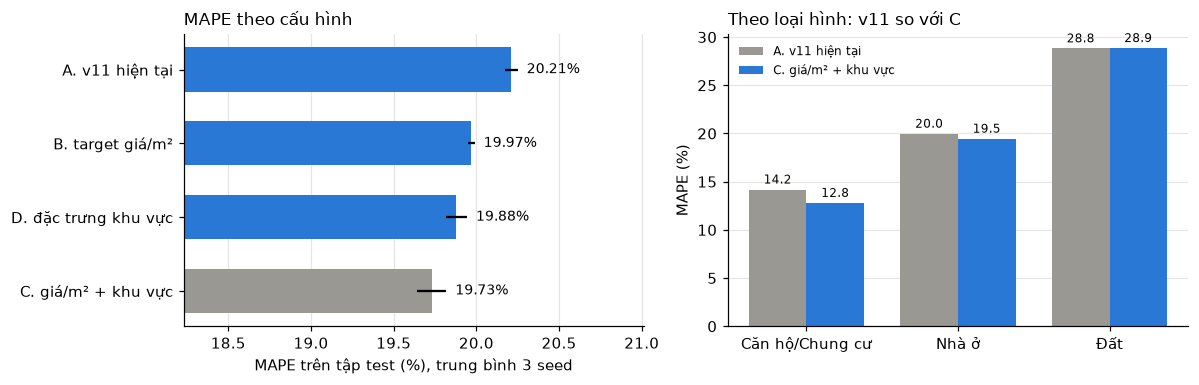

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot = results["mape"] * 100
bars = axes[0].barh(plot.index[::-1], plot.values[::-1],
                    xerr=results["mape_std_3_seed"].values[::-1] * 100,
                    color=[GRAY] + [BLUE] * 3, height=0.6)
axes[0].bar_label(bars, labels=[f"{v:.2f}%" for v in plot.values[::-1]], padding=6, fontsize=9)
axes[0].set_xlim(plot.min() - 1.5, plot.max() + 0.8)
axes[0].set_xlabel("MAPE trên tập test (%), trung bình 3 seed")
axes[0].set_title("MAPE theo cấu hình", loc="left", fontsize=11)
axes[0].grid(axis="y", visible=False)

types = [c for c in by_type.columns if c != "Tất cả"]
x = np.arange(len(types))
for i, (name, color) in enumerate([("A. v11 hiện tại", GRAY), ("C. giá/m² + khu vực", BLUE)]):
    b = axes[1].bar(x + (i - 0.5) * 0.38, by_type.loc[name, types], width=0.38, color=color, label=name)
    axes[1].bar_label(b, labels=[f"{v:.1f}" for v in by_type.loc[name, types]], padding=2, fontsize=8)
axes[1].set_xticks(x, types)
axes[1].set_ylabel("MAPE (%)")
axes[1].set_title("Theo loại hình: v11 so với C", loc="left", fontsize=11)
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 6. Đặc trưng quan trọng của cấu hình C

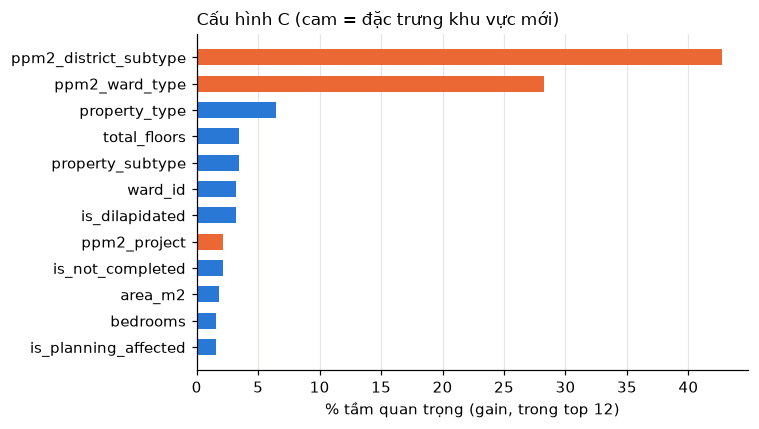

In [8]:
m = models["C. giá/m² + khu vực"]
imp = pd.Series(m.named_steps["model"].feature_importances_,
                index=m.named_steps["prep"].get_feature_names_out()).nlargest(12)
imp = imp / imp.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index[::-1], imp.values[::-1],
        color=[ORANGE if c in AREA else BLUE for c in imp.index[::-1]], height=0.6)
ax.set_xlabel("% tầm quan trọng (gain, trong top 12)")
ax.set_title("Cấu hình C (cam = đặc trưng khu vực mới)", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 7. Kết luận

In [9]:
a, c = results.loc["A. v11 hiện tại"], results.loc["C. giá/m² + khu vực"]
print(f"v11 hiện tại : MAPE {a.mape:.2%} | MdAPE {a.mdape:.2%} | {a.within_20pct:.1%} tin sai <= 20%")
print(f"Cấu hình C   : MAPE {c.mape:.2%} | MdAPE {c.mdape:.2%} | {c.within_20pct:.1%} tin sai <= 20%")
print(f"Giảm {(a.mape - c.mape) * 100:.2f} điểm MAPE ({1 - c.mape / a.mape:.1%} tương đối); "
      f"dao động giữa các seed chỉ khoảng ±{max(a.mape_std_3_seed, c.mape_std_3_seed) * 100:.2f} điểm.")
for t in types:
    print(f"  {t:<18} {by_type.loc['A. v11 hiện tại', t]:.2f}% -> {by_type.loc['C. giá/m² + khu vực', t]:.2f}%")

v11 hiện tại : MAPE 20.21% | MdAPE 14.14% | 64.9% tin sai <= 20%
Cấu hình C   : MAPE 19.73% | MdAPE 13.73% | 65.9% tin sai <= 20%
Giảm 0.48 điểm MAPE (2.4% tương đối); dao động giữa các seed chỉ khoảng ±0.09 điểm.
  Căn hộ/Chung cư    14.18% -> 12.79%
  Nhà ở              19.97% -> 19.45%
  Đất                28.83% -> 28.86%


## 8. Cải thiện riêng cho đất

Đất là loại sai nhiều nhất. Trước khi thử, xem sai số của đất đến từ đâu (cấu hình C, seed 42).

In [10]:
C_NAME = "C. giá/m² + khu vực"
err = test.assign(ape=ape_by_exp[C_NAME])
land_err = err[err["property_type"] == "Đất"]
print(f"Đất: MAPE {land_err.ape.mean():.1%}, MdAPE {land_err.ape.median():.1%}; "
      f"5% tin sai nhất chiếm {land_err.ape.nlargest(len(land_err) // 20).sum() / land_err.ape.sum():.0%} tổng sai số")
display(land_err.groupby("property_subtype").agg(so_tin=("ape", "size"), mape=("ape", "mean"), mdape=("ape", "median")))
land_err.groupby(pd.cut(land_err["area_m2"], [0, 60, 100, 200, 500, np.inf]), observed=True).agg(
    so_tin=("ape", "size"), mape=("ape", "mean"), mdape=("ape", "median"))

Đất: MAPE 28.9%, MdAPE 18.4%; 5% tin sai nhất chiếm 30% tổng sai số


,so_tin,mape,mdape
property_subtype,,,
Đất công nghiệp,2,0.0699,0.0699
Đất nông nghiệp,51,0.6048,0.3322
Đất nền dự án,24,0.1716,0.1082
Đất thổ cư,561,0.2656,0.1831


,so_tin,mape,mdape
area_m2,,,
"(0.0, 60.0]",81,0.1838,0.1019
"(60.0, 100.0]",212,0.2225,0.1362
"(100.0, 200.0]",176,0.3037,0.2170
"(200.0, 500.0]",111,0.3836,0.2450
"(500.0, inf]",58,0.4489,0.3381


Sai số tập trung ở **đất nông nghiệp** và **lô lớn**. Những lô này thường chỉ có một phần là thổ cư,
nên giá/m² thấp hơn nhiều so với lô thổ cư nhỏ cùng phường. Thông tin "bao nhiêu m² thổ cư"
chỉ có trong tiêu đề/mô tả tin đăng (`silver.listing_current`), không có trong bảng đặc trưng.

Thử 3 hướng:
1. **Lọc nhiễu** tập train: bỏ tin có log(giá/m²) lệch quá `k` lần MAD so với trung vị của
   (quận × loại con). Tập test giữ nguyên.
2. **Mô hình riêng cho đất**: một XGBoost chỉ học trên tin đất; các loại khác dùng mô hình chung.
3. **Thuộc tính thổ cư** trích từ văn bản: `residential_area_m2`, `residential_ratio`, `is_full_residential`.

In [11]:
import re

text = DeltaTable("s3://lakehouse/warehouse/silver.db/listing_current", storage_options=STORAGE).to_pandas(
    columns=["listing_key", "title", "description"]).set_index("listing_key")
raw = df["listing_key"].map((text["title"].fillna("") + " . " + text["description"].fillna("")).str.lower()).fillna("")

NUM = r"(\d+(?:[.,]\d+)?)\s*(?:m2|m²|m\b|mét)"
before = raw.str.extract(r"(?:thổ cư|tc|đất ở|odt|ont)\s*(?:là|:|-)?\s*" + NUM)[0]   # "thổ cư 100m2"
after = raw.str.extract(NUM + r"\s*(?:đất\s*)?(?:thổ cư|tc\b|đất ở|odt|ont)")[0]    # "100m2 thổ cư"
res_area = pd.to_numeric(before.fillna(after).str.replace(",", "."), errors="coerce")
res_area = res_area.where((res_area > 0) & (res_area <= df["area_m2"] * 1.01))
full = raw.str.contains(r"full\s*thổ cư|100\s*%\s*thổ cư|toàn bộ thổ cư|thổ cư 100")
res_area = res_area.where(~full, df["area_m2"])
is_land = df["property_type"] == "Đất"
RESIDENTIAL = pd.DataFrame({
    "residential_area_m2": res_area.where(is_land),
    "residential_ratio": (res_area / df["area_m2"]).where(is_land),
    "is_full_residential": full.astype(float).where(is_land),
})
land = df[is_land]
print("Tỷ lệ tin đất trích được diện tích thổ cư:")
RESIDENTIAL[is_land].assign(subtype=land["property_subtype"], lon=land["area_m2"] > 200).groupby(
    ["subtype", "lon"])["residential_area_m2"].apply(lambda s: s.notna().mean()).rename("% có").to_frame()

Tỷ lệ tin đất trích được diện tích thổ cư:


% có
subtype         lon         
Đất công nghiệp False 0.0000
                True  0.0435
Đất nông nghiệp False 0.0208
                True  0.1322
Đất nền dự án   False 0.0357
                True  0.0645
Đất thổ cư      False 0.3265
                True  0.5586

In [12]:
def noise_mask(frame, k):
    y = np.log(frame["price_vnd"] / frame["area_m2"])
    groups = [frame["district_id"], frame["property_subtype"]]
    median = y.groupby(groups).transform("median")
    mad = (y - median).abs().groupby(groups).transform("median") * 1.4826
    return (y - median).abs() / mad.clip(lower=0.05) <= k


def fit_predict(tr, te, residential=False, seed=42):
    """Cấu hình C, tùy chọn thêm thuộc tính thổ cư."""
    a_tr, a_te = area_features(tr, te)
    x_tr, x_te, extra = prepare(tr).join(a_tr), prepare(te).join(a_te), list(a_tr.columns)
    if residential:
        x_tr, x_te = x_tr.join(RESIDENTIAL.loc[tr.index]), x_te.join(RESIDENTIAL.loc[te.index])
        extra += list(RESIDENTIAL.columns)
    model = build_model(extra, seed).fit(x_tr, np.log(tr["price_vnd"] / tr["area_m2"]))
    return pd.Series(np.exp(model.predict(x_te)) * te["area_m2"].to_numpy(), index=te.index)


def with_land_model(tr, te, residential, seed):
    pred = fit_predict(tr, te, residential, seed)
    land_tr, land_te = tr["property_type"] == "Đất", te["property_type"] == "Đất"
    pred.loc[te.index[land_te]] = fit_predict(tr[land_tr], te[land_te], residential, seed)
    return pred


LAND_EXPERIMENTS = {
    "C (mốc so sánh)": lambda s: fit_predict(train, test, seed=s),
    "C + lọc nhiễu k=3": lambda s: fit_predict(train[noise_mask(train, 3)], test, seed=s),
    "C + lọc nhiễu k=5": lambda s: fit_predict(train[noise_mask(train, 5)], test, seed=s),
    "C + mô hình riêng đất": lambda s: with_land_model(train, test, False, s),
    "C + thuộc tính thổ cư": lambda s: fit_predict(train, test, True, s),
    "C + riêng đất + thổ cư": lambda s: with_land_model(train, test, True, s),
    "C + thổ cư + lọc k=5": lambda s: fit_predict(train[noise_mask(train, 5)], test, True, s),
}
for k in (3, 5):
    m = noise_mask(train, k)
    print(f"lọc k={k}: bỏ {(~m).sum()} tin train ({(~m).mean():.1%}), trong đó {(~m & (train.property_type == 'Đất')).sum()} tin đất")

land_rows = []
for name, run_fn in LAND_EXPERIMENTS.items():
    apes = [((p := run_fn(s)) - test["price_vnd"]).abs() / test["price_vnd"] for s in SEEDS]
    mean_ape = pd.concat(apes, axis=1).mean(axis=1)
    row = {"cau_hinh": name, "mape": np.mean([a.mean() for a in apes]),
           "mape_std_3_seed": np.std([a.mean() for a in apes])}
    row.update((mean_ape.groupby(test["property_type"]).mean() * 100).add_prefix("mape_% ").to_dict())
    land_rows.append(row)
    print(f"{name:<24} MAPE {row['mape']:.2%} | đất {row['mape_% Đất']:.2f}%")
land_results = pd.DataFrame(land_rows).set_index("cau_hinh")
land_results

lọc k=3: bỏ 456 tin train (1.2%), trong đó 63 tin đất
lọc k=5: bỏ 31 tin train (0.1%), trong đó 6 tin đất


C (mốc so sánh)          MAPE 19.73% | đất 29.48%


C + lọc nhiễu k=3        MAPE 19.95% | đất 29.04%


C + lọc nhiễu k=5        MAPE 19.60% | đất 28.98%


C + mô hình riêng đất    MAPE 19.70% | đất 29.21%


C + thuộc tính thổ cư    MAPE 19.83% | đất 29.17%


C + riêng đất + thổ cư   MAPE 19.77% | đất 28.62%


C + thổ cư + lọc k=5     MAPE 19.54% | đất 28.19%


,mape,mape_std_3_seed,mape_% Căn hộ/Chung cư,mape_% Nhà ở,mape_% Đất
cau_hinh,,,,,
C (mốc so sánh),0.1973,0.0009,12.8550,19.5032,29.4753
C + lọc nhiễu k=3,0.1995,0.0001,13.1384,19.8120,29.0381
C + lọc nhiễu k=5,0.1960,0.0003,12.7036,19.4325,28.9755
C + mô hình riêng đất,0.1970,0.0006,12.8550,19.5032,29.2125
C + thuộc tính thổ cư,0.1983,0.0007,13.0769,19.6349,29.1671
C + riêng đất + thổ cư,0.1977,0.0002,13.0769,19.6349,28.6221
C + thổ cư + lọc k=5,0.1954,0.0003,12.7110,19.4677,28.1927


**Đọc bảng:** cột theo loại hình lấy trung bình 3 seed. Các loại không bị đụng tới (căn hộ, nhà ở)
vẫn dao động khoảng ±0,3 điểm giữa các cấu hình, nên đây là mức nhiễu. Chênh lệch nhỏ hơn mức này
thì không nên coi là cải thiện. Tập test chỉ có khoảng 640 tin đất, và 5% tin sai nhất chiếm khoảng 30%
tổng sai số, nên MAPE của đất rất nhạy với vài tin cá biệt.